In [1]:
import sys
import os
import pandas as pd

# Thêm thư mục gốc của dự án vào đường dẫn tìm kiếm module của Python
sys.path.append(os.path.abspath('..'))

feature_cols = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
target_cols = ['CO', 'NOX']  # Lấy CO gốc và NOX gốc (tuyệt đối không dùng CO_clipped cho Test)

# Đọc trực tiếp 2 file đã làm sạch và chia theo năm từ Notebook 01
train_raw = pd.read_csv('../data/processed/train_clean.csv')
test_raw = pd.read_csv('../data/processed/test_clean.csv')

X_train, y_train = train_raw[feature_cols], train_raw[target_cols]
X_test, y_test = test_raw[feature_cols], test_raw[target_cols]

# Tạo bản y_train_clipped (lấy cột CO_clipped đã tính P99 trên Train từ Notebook 01)
y_train_clipped = y_train.copy()
y_train_clipped['CO'] = train_raw['CO_clipped']

p99_co_train = y_train['CO'].quantile(0.99)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Ngưỡng P99 CO (chỉ tính trên Train): {p99_co_train:.4f}")

Train: (22191, 9) | Test: (14535, 9)
Ngưỡng P99 CO (chỉ tính trên Train): 10.7166


In [2]:
from src.models import build_xgboost_model

model = build_xgboost_model()
model.fit(X_train, y_train_clipped)
y_pred = model.predict(X_test)

In [3]:
y_pred

array([[  2.8200238,  77.76272  ],
       [  3.035232 ,  77.80868  ],
       [  3.1612866,  73.467064 ],
       ...,
       [  8.661856 , 107.06805  ],
       [  2.314913 ,  85.64815  ],
       [  4.1415267,  89.57772  ]], shape=(14535, 2), dtype=float32)

In [4]:
from src.evaluation import evaluate_regression

results_co = evaluate_regression(y_test.iloc[:, 0], y_pred[:, 0], model_name="XGBoost Baseline - CO")
results_nox = evaluate_regression(y_test.iloc[:, 1], y_pred[:, 1], model_name="XGBoost Baseline - NOX")

=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Baseline - CO ===
MSE  : 2.3282
RMSE : 1.5258
MAE  : 0.9001
R2   : 0.5145
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Baseline - NOX ===
MSE  : 174.3442
RMSE : 13.2039
MAE  : 11.4513
R2   : -0.5585


In [5]:
import time
from src.models import tune_xgboost
from src.evaluation import evaluate_regression

# 1. Tách biến mục tiêu
y_train_co, y_test_co = y_train.iloc[:, 0], y_test.iloc[:, 0]
y_train_nox, y_test_nox = y_train.iloc[:, 1], y_test.iloc[:, 1]

# 2. Tuning cho CO (clip_p99=True để tính P99 riêng trong từng fold của CV)
print("--- Đang Tuning cho mô hình CO ---")
start_time_co = time.time()

best_model_co, best_params_co, cv_results_co = tune_xgboost(
    X_train, y_train_co, n_iter=15, cv=3, random_state=42, clip_p99=True
)

time_co = time.time() - start_time_co
print(f"[THỜI GIAN TUNING CO]: {time_co:.2f}s")
print("[BỘ THAM SỐ TỐI ƯU CHO CO]:", best_params_co)

y_pred_co_tuned = best_model_co.predict(X_test)
results_co_tuned = evaluate_regression(y_test_co, y_pred_co_tuned, model_name="XGBoost Tuned - CO")

# 3. Tuning cho NOX (clip_p99=False vì NOX không clip outlier)
print("\n--- Đang Tuning cho mô hình NOX ---")
start_time_nox = time.time()

best_model_nox, best_params_nox, cv_results_nox = tune_xgboost(
    X_train, y_train_nox, n_iter=15, cv=3, random_state=42, clip_p99=False
)

time_nox = time.time() - start_time_nox
print(f"[THỜI GIAN TUNING NOX]: {time_nox:.2f}s")
print("[BỘ THAM SỐ TỐI ƯU CHO NOX]:", best_params_nox)

y_pred_nox_tuned = best_model_nox.predict(X_test)
results_nox_tuned = evaluate_regression(y_test_nox, y_pred_nox_tuned, model_name="XGBoost Tuned - NOX")

--- Đang Tuning cho mô hình CO ---
[THỜI GIAN TUNING CO]: 33.35s
[BỘ THAM SỐ TỐI ƯU CHO CO]: {'subsample': 0.8, 'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - CO ===
MSE  : 2.2493
RMSE : 1.4998
MAE  : 0.8809
R2   : 0.5309

--- Đang Tuning cho mô hình NOX ---
[THỜI GIAN TUNING NOX]: 29.50s
[BỘ THAM SỐ TỐI ƯU CHO NOX]: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 9, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
=== KẾT QUẢ ĐÁNH GIÁ: XGBoost Tuned - NOX ===
MSE  : 146.5625
RMSE : 12.1063
MAE  : 10.6433
R2   : -0.3102


In [6]:
import time
from sklearn.metrics import r2_score
import xgboost as xgb

# 1. Với XGBoost Baseline (CO): fit trên y_train_clipped['CO']
t0 = time.time()
xgb_base = xgb.XGBRegressor(random_state=42)
xgb_base.fit(X_train, y_train_clipped['CO'])
time_base = time.time() - t0

r2_train_base = r2_score(y_train_clipped['CO'], xgb_base.predict(X_train))
print(f"XGB Baseline CO - R2_train: {r2_train_base:.4f}, Thời gian fit: {time_base:.4f}s")

# 2. Với XGBoost Tuned (CO) - best_model_co đã có từ RandomizedSearch:
y_train_pred_tuned = best_model_co.predict(X_train)
r2_train_tuned = r2_score(y_train_co, y_train_pred_tuned)
print(f"XGB Tuned CO - R2_train: {r2_train_tuned:.4f}")

XGB Baseline CO - R2_train: 0.9294, Thời gian fit: 0.1532s
XGB Tuned CO - R2_train: 0.8189


In [7]:
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import wilcoxon
import numpy as np

# Huấn luyện nhanh Random Forest đối chứng trên y_train_clipped['CO']
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train_clipped['CO'])
y_pred_rf = rf.predict(X_test)

# So sánh với XGBoost Tuned trên y_test_co gốc
e_xgb = np.abs(y_test_co.values - y_pred_co_tuned)
e_rf  = np.abs(y_test_co.values - y_pred_rf)

stat, p_val = wilcoxon(e_xgb, e_rf)
print(f"Delta MAE: {e_xgb.mean() - e_rf.mean():.4f}")
print(f"p-value: {p_val:.3e}")

Delta MAE: 0.0034
p-value: 2.395e-01


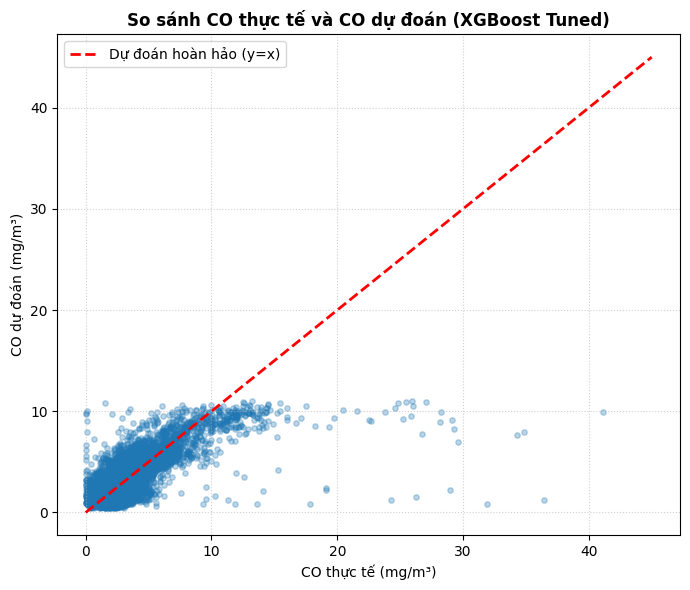

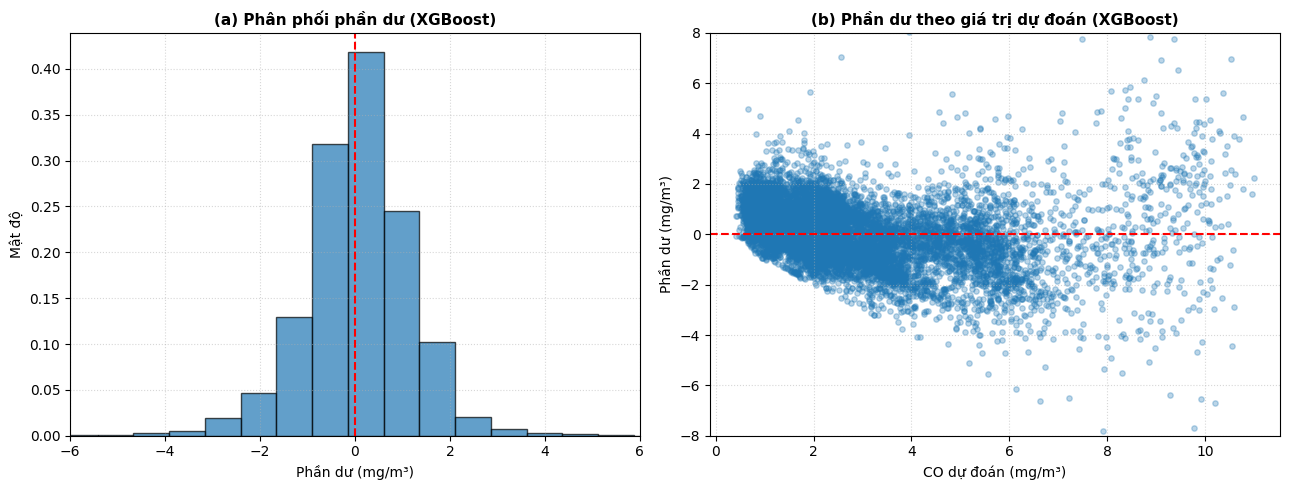

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Tính phần dư của XGBoost Tuned (CO)
residuals_xgb = y_test_co.values - y_pred_co_tuned

# 1. Vẽ hình Actual vs Predicted của XGBoost
plt.figure(figsize=(7, 6))
plt.scatter(
    y_test_co.values, y_pred_co_tuned, alpha=0.3, s=15, color='#1f77b4'
)
plt.plot(
    [0, 45],
    [0, 45],
    'r--',
    linewidth=2,
    label='Dự đoán hoàn hảo (y=x)',
)
plt.title(
    'So sánh CO thực tế và CO dự đoán (XGBoost Tuned)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('CO thực tế (mg/m³)')
plt.ylabel('CO dự đoán (mg/m³)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(
    '../reports/figures/actual_vs_predicted_xgb.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

# 2. Vẽ 2 hình chẩn đoán phần dư (Residual Distribution & Residual vs Predicted)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Phân phối phần dư
axes[0].hist(
    residuals_xgb,
    bins=60,
    color='#1f77b4',
    edgecolor='black',
    alpha=0.7,
    density=True,
)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title(
    '(a) Phân phối phần dư (XGBoost)', fontsize=11, fontweight='bold'
)
axes[0].set_xlabel('Phần dư (mg/m³)')
axes[0].set_ylabel('Mật độ')
axes[0].set_xlim(-6, 6)
axes[0].grid(True, linestyle=':', alpha=0.5)

# (b) Phần dư theo giá trị dự đoán
axes[1].scatter(
    y_pred_co_tuned, residuals_xgb, alpha=0.3, s=15, color='#1f77b4'
)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title(
    '(b) Phần dư theo giá trị dự đoán (XGBoost)',
    fontsize=11,
    fontweight='bold',
)
axes[1].set_xlabel('CO dự đoán (mg/m³)')
axes[1].set_ylabel('Phần dư (mg/m³)')
axes[1].set_ylim(-8, 8)
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig(
    '../reports/figures/residual_diagnostics_xgb.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

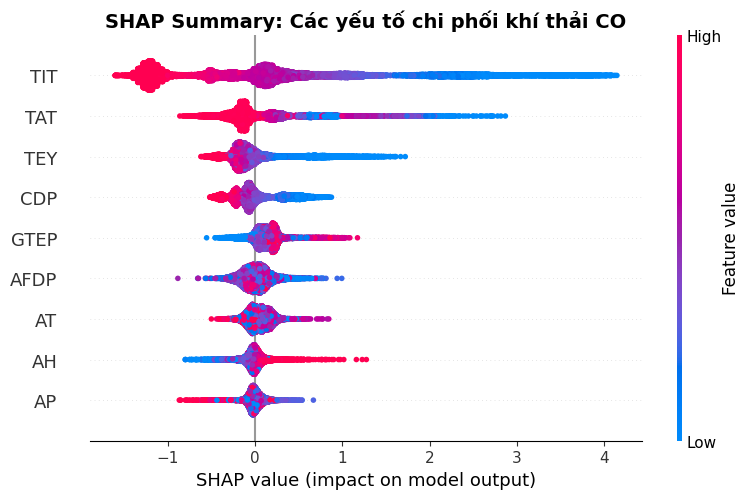

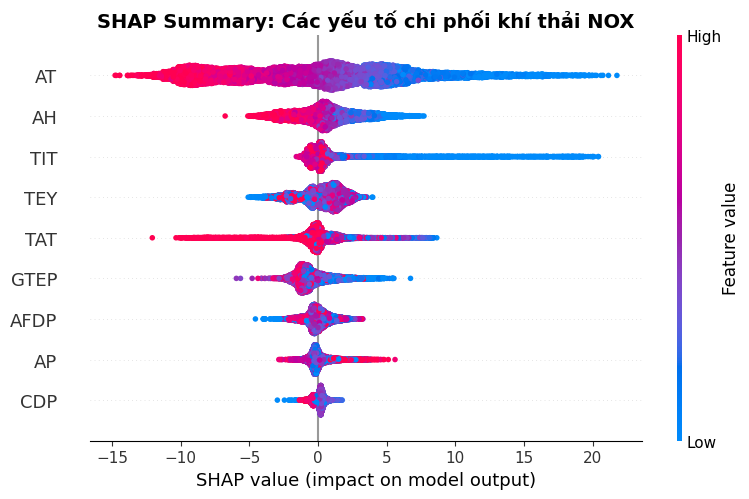

In [9]:
import shap
import matplotlib.pyplot as plt

# Khởi tạo bộ tính toán SHAP cho CO
explainer_co = shap.TreeExplainer(best_model_co)
shap_values_co = explainer_co.shap_values(X_test)

# Khởi tạo bộ tính toán SHAP cho mô hình NOX
explainer_nox = shap.TreeExplainer(best_model_nox)
shap_values_nox = explainer_nox.shap_values(X_test)

# Vẽ biểu đồ Tổng quan (Summary Plot) cho Co
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải CO", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_co, X_test, show=False)
plt.show()

# Vẽ biểu đồ Tổng quan (Summary Plot) cho NOX
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải NOX", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_nox, X_test, show=False)
plt.show()



In [10]:
import joblib
import os
import matplotlib.pyplot as plt
import shap

os.makedirs('../models', exist_ok=True)
os.makedirs('../reports/figures', exist_ok=True)

joblib.dump(best_model_co, '../models/xgboost_tuned_co.pkl')
joblib.dump(best_model_nox, '../models/xgboost_tuned_nox.pkl')
print('Lưu mô hình vào ../models')

# Vẽ biểu đồ Tổng quan (Summary Plot) cho Co
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải CO", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_co, X_test, show=False)
plt.savefig('../reports/figures/shap_summary_co.png', dpi=300, bbox_inches='tight')
plt.close()

# Vẽ biểu đồ Tổng quan (Summary Plot) cho NOX
plt.figure(figsize=(10,6))
plt.title("SHAP Summary: Các yếu tố chi phối khí thải NOX", fontsize=14, fontweight='bold')
shap.summary_plot(shap_values_nox, X_test, show=False)
plt.savefig('../reports/figures/shap_summary_nox.png', dpi=300, bbox_inches='tight')
plt.close()




Lưu mô hình vào ../models


In [11]:
import pandas as pd
import os

os.makedirs('../reports/log', exist_ok=True)

cols_to_keep = ['params', 'mean_test_score', 'std_test_score', 'mean_fit_time']

# 1. Trích xuất và lưu lịch sử dò tìm của CO
cv_df_co = pd.DataFrame(cv_results_co)
log_co = cv_df_co[cols_to_keep].sort_values(by='mean_test_score', ascending=False)
log_co.to_csv('../reports/log/tuning_log_co.csv', index=False)

# 2. Trích xuất và lưu lịch sử dò tìm của NOX
cv_df_nox = pd.DataFrame(cv_results_nox)
log_nox = cv_df_nox[cols_to_keep].sort_values(by='mean_test_score', ascending=False)
log_nox.to_csv('../reports/log/tuning_log_nox.csv', index=False)

print("Đã lưu log tuning thành công vào thư mục reports/log/")
log_co.head(3)

Đã lưu log tuning thành công vào thư mục reports/log/


,params,mean_test_score,std_test_score,mean_fit_time
8,"{'subsample': 0.8, 'n_estimators': 500, 'max_d...",0.709782,0.011381,1.101236
12,"{'subsample': 1.0, 'n_estimators': 200, 'max_d...",0.709772,0.009992,1.035055
1,"{'subsample': 0.8, 'n_estimators': 500, 'max_d...",0.706685,0.010187,0.740021
